In [ ]:
!pip install astropy

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar archivo limpio con FE_H, X_gal, Y_gal, Z_gal
df = pd.read_csv("clean.csv")

# Filtrar solo estrellas con FE_H válido
df = df[df['FE_H'].notnull()].copy()

# Columnas derivadas
df['Z_abs'] = np.abs(df['Z_gal'])
df['R_GC'] = np.sqrt(df['X_gal']**2 + df['Y_gal']**2)

# Inicializar columna
df['Component'] = 'Unclassified'

# Aplicar los filtros exactamente como en TOPCAT
df.loc[(df['FE_H'] > -0.5) & (df['Z_abs'] < 0.3) & (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thin Disk'

df.loc[(df['FE_H'] > -1.3) & (df['FE_H'] <= -0.3) &
       (df['Z_abs'] >= 0.5) & (df['Z_abs'] < 1.5) &
       (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thick Disk'

df.loc[(df['FE_H'] < -1.5) & ((df['Z_abs'] > 5) | (df['R_GC'] > 15)), 'Component'] = 'Halo'

df.loc[(df['FE_H'] > -1.5) & (df['R_GC'] < 3) & (df['Z_abs'] < 1.5), 'Component'] = 'Bulge'

df.loc[(df['R_GC'] >= 7.7) & (df['R_GC'] <= 8.7) & (df['Z_abs'] < 0.3), 'Component'] = 'Solar Neighbourhood'

# Ver resultado
print(df['Component'].value_counts())

# (opcional) guardar archivo con clasificación
# df.to_csv("clean_classified.csv", index=False)


<ipython-input-26-3d065cf3fcbd>:6: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")


Component
Unclassified           159235
Solar Neighbourhood     68243
Thick Disk              23370
Thin Disk               20049
Bulge                    2154
Halo                      633
Name: count, dtype: int64


<ipython-input-8-0292c52f98df>:8: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")
<ipython-input-8-0292c52f98df>:77: RuntimeWarning: invalid value encountered in sqrt
  v_perp = np.sqrt(v_tot**2 - v**2)


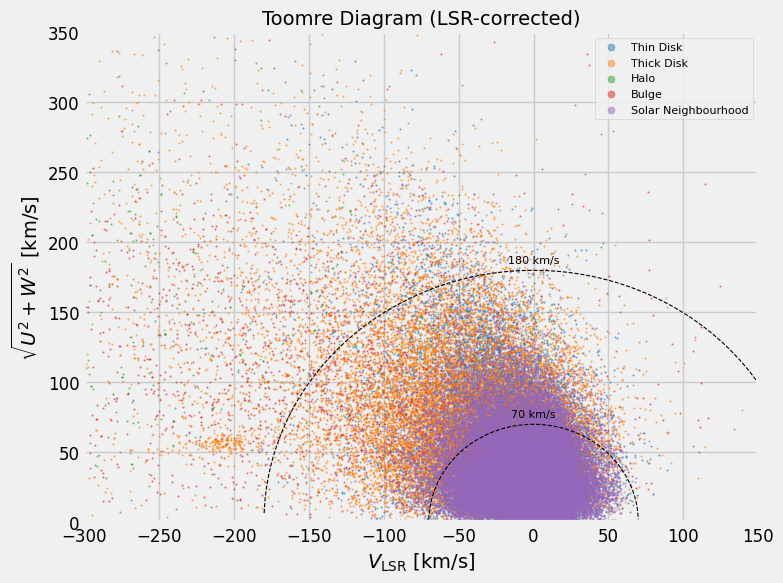

In [ ]:
from astropy.coordinates import SkyCoord, Galactocentric
import astropy.units as u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar archivo
df = pd.read_csv("clean.csv")

# Filtrar columnas necesarias
cols_needed = ['RA', 'DEC', 'GAIAEDR3_PMRA', 'GAIAEDR3_PMDEC',
               'distance_pc', 'VHELIO_AVG', 'X_gal', 'Y_gal', 'Z_gal', 'FE_H']
df = df.dropna(subset=cols_needed).copy()

# Calcular Z_abs y R_GC
df['Z_abs'] = np.abs(df['Z_gal'])
df['R_GC'] = np.sqrt(df['X_gal']**2 + df['Y_gal']**2)

# Calcular velocidades U, V, W
c_icrs = SkyCoord(
    ra=df['RA'].values * u.deg,
    dec=df['DEC'].values * u.deg,
    distance=df['distance_pc'].values * u.pc,
    pm_ra_cosdec=df['GAIAEDR3_PMRA'].values * u.mas/u.yr,
    pm_dec=df['GAIAEDR3_PMDEC'].values * u.mas/u.yr,
    radial_velocity=df['VHELIO_AVG'].values * u.km/u.s,
    frame='icrs'
)

c_galcen = c_icrs.transform_to(Galactocentric())
uvw = c_galcen.velocity.d_xyz.to(u.km/u.s)
df['U'] = uvw[0].value
df['V'] = uvw[1].value
df['W'] = uvw[2].value
df['V_perp'] = np.sqrt(df['U']**2 + df['W']**2)

# Corregir V al Sistema Local de Reposo (LSR)
V_sun = 232  # km/s (velocidad circular del LSR)
df['V_LSR'] = df['V'] - V_sun

# Clasificación galáctica
df['Component'] = 'Unclassified'
df.loc[(df['FE_H'] > -0.5) & (df['Z_abs'] < 0.3) & (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thin Disk'
df.loc[(df['FE_H'] > -1.3) & (df['FE_H'] <= -0.3) &
       (df['Z_abs'] >= 0.5) & (df['Z_abs'] < 1.5) &
       (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thick Disk'
df.loc[(df['FE_H'] < -1.5) & ((df['Z_abs'] > 5) | (df['R_GC'] > 15)), 'Component'] = 'Halo'
df.loc[(df['FE_H'] > -1.5) & (df['R_GC'] < 3) & (df['Z_abs'] < 1.5), 'Component'] = 'Bulge'
df.loc[(df['R_GC'] >= 7.7) & (df['R_GC'] <= 8.7) & (df['Z_abs'] < 0.3), 'Component'] = 'Solar Neighbourhood'

# Paleta de colores
component_colors = {
    'Thin Disk': '#1f77b4',
    'Thick Disk': '#ff7f0e',
    'Halo': '#2ca02c',
    'Bulge': '#d62728',
    'Solar Neighbourhood': '#9467bd'
}
df['Color'] = df['Component'].map(component_colors)

# Filtrar clasificados
df_classified = df[df['Component'].isin(component_colors.keys())]

# Gráfico Toomre centrado en LSR
plt.figure(figsize=(8, 6))
for comp, color in component_colors.items():
    subset = df_classified[df_classified['Component'] == comp]
    plt.scatter(subset['V_LSR'], subset['V_perp'], s=1, alpha=0.5, color=color, label=comp)

plt.xlabel(r'$V_{\mathrm{LSR}}$ [km/s]')
plt.ylabel(r'$\sqrt{U^2 + W^2}$ [km/s]')
plt.title('Toomre Diagram (LSR-corrected)')

# Isocontornos de velocidad total
for v_tot in [70,180]:
    v = np.linspace(-300, 300, 1000)
    v_perp = np.sqrt(v_tot**2 - v**2)
    v_perp = np.where(np.isreal(v_perp), v_perp, np.nan)
    plt.plot(v, v_perp, 'k--', linewidth=0.8)
    plt.text(0, v_tot + 5, f'{v_tot} km/s', ha='center', fontsize=8)

plt.grid(True)
plt.legend(markerscale=5, fontsize=8, loc='upper right')
plt.xlim(-300, 150)
plt.ylim(0, 350)
plt.tight_layout()
plt.show()


<ipython-input-23-b04982c8ff39>:8: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")
<ipython-input-23-b04982c8ff39>:74: RuntimeWarning: invalid value encountered in sqrt
  v_perp = np.sqrt(v_tot**2 - v**2)


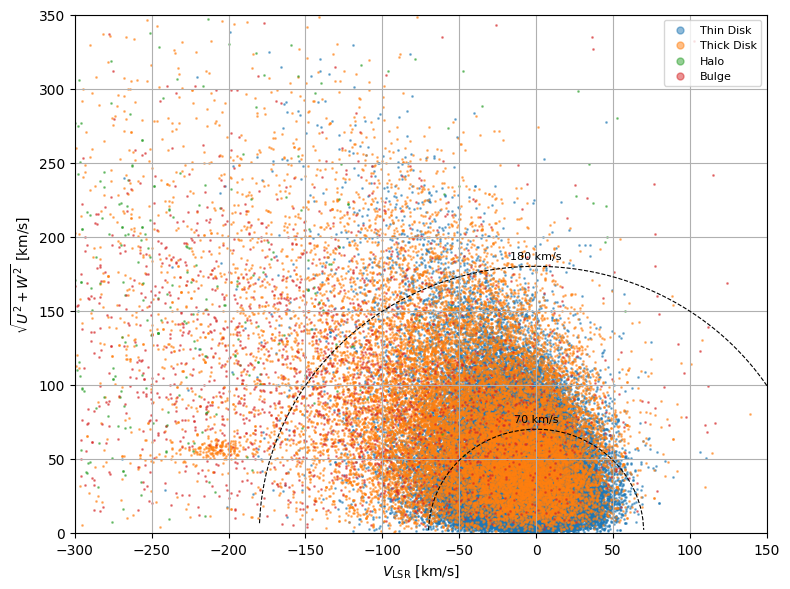

In [ ]:
from astropy.coordinates import SkyCoord, Galactocentric
import astropy.units as u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar archivo
df = pd.read_csv("clean.csv")

# Filtrar columnas necesarias
cols_needed = ['RA', 'DEC', 'GAIAEDR3_PMRA', 'GAIAEDR3_PMDEC',
               'distance_pc', 'VHELIO_AVG', 'X_gal', 'Y_gal', 'Z_gal', 'FE_H']
df = df.dropna(subset=cols_needed).copy()

# Calcular Z_abs y R_GC
df['Z_abs'] = np.abs(df['Z_gal'])
df['R_GC'] = np.sqrt(df['X_gal']**2 + df['Y_gal']**2)

# Calcular velocidades U, V, W
c_icrs = SkyCoord(
    ra=df['RA'].values * u.deg,
    dec=df['DEC'].values * u.deg,
    distance=df['distance_pc'].values * u.pc,
    pm_ra_cosdec=df['GAIAEDR3_PMRA'].values * u.mas/u.yr,
    pm_dec=df['GAIAEDR3_PMDEC'].values * u.mas/u.yr,
    radial_velocity=df['VHELIO_AVG'].values * u.km/u.s,
    frame='icrs'
)

c_galcen = c_icrs.transform_to(Galactocentric())
uvw = c_galcen.velocity.d_xyz.to(u.km/u.s)
df['U'] = uvw[0].value
df['V'] = uvw[1].value
df['W'] = uvw[2].value
df['V_perp'] = np.sqrt(df['U']**2 + df['W']**2)

# Corregir al LSR
V_sun = 232  # km/s
df['V_LSR'] = df['V'] - V_sun

# Clasificación sin Solar Neighbourhood
df['Component'] = 'Unclassified'
df.loc[(df['FE_H'] > -0.5) & (df['Z_abs'] < 0.3) & (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thin Disk'
df.loc[(df['FE_H'] > -1.3) & (df['FE_H'] <= -0.3) &
       (df['Z_abs'] >= 0.5) & (df['Z_abs'] < 1.5) &
       (df['R_GC'] >= 3) & (df['R_GC'] < 10), 'Component'] = 'Thick Disk'
df.loc[(df['FE_H'] < -1.5) & ((df['Z_abs'] > 5) | (df['R_GC'] > 15)), 'Component'] = 'Halo'
df.loc[(df['FE_H'] > -1.5) & (df['R_GC'] < 3) & (df['Z_abs'] < 1.5), 'Component'] = 'Bulge'

# Paleta de colores
component_colors = {
    'Thin Disk': '#1f77b4',
    'Thick Disk': '#ff7f0e',
    'Halo': '#2ca02c',
    'Bulge': '#d62728'
}
df['Color'] = df['Component'].map(component_colors)

# Filtrar clasificados
df_classified = df[df['Component'].isin(component_colors.keys())]

# Gráfico Toomre corregido al LSR
plt.figure(figsize=(8, 6))
for comp, color in component_colors.items():
    subset = df_classified[df_classified['Component'] == comp]
    plt.scatter(subset['V_LSR'], subset['V_perp'], s=1, alpha=0.5, color=color, label=comp)

plt.xlabel(r'$V_{\mathrm{LSR}}$ [km/s]')
plt.ylabel(r'$\sqrt{U^2 + W^2}$ [km/s]')

# Líneas de energía constante
for v_tot in [70, 180]:
    v = np.linspace(-300, 300, 1000)
    v_perp = np.sqrt(v_tot**2 - v**2)
    v_perp = np.where(np.isreal(v_perp), v_perp, np.nan)
    plt.plot(v, v_perp, 'k--', linewidth=0.8)
    plt.text(0, v_tot + 5, f'{v_tot} km/s', ha='center', fontsize=8)

plt.grid(True)
plt.legend(markerscale=5, fontsize=8, loc='upper right')

# Zoom personalizado
plt.xlim(-300, 150)
plt.ylim(0, 350)

plt.tight_layout()
plt.show()


<ipython-input-25-05daaf4f6d69>:8: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")
<ipython-input-25-05daaf4f6d69>:53: RuntimeWarning: invalid value encountered in sqrt
  v_perp = np.sqrt(v_tot**2 - v**2)


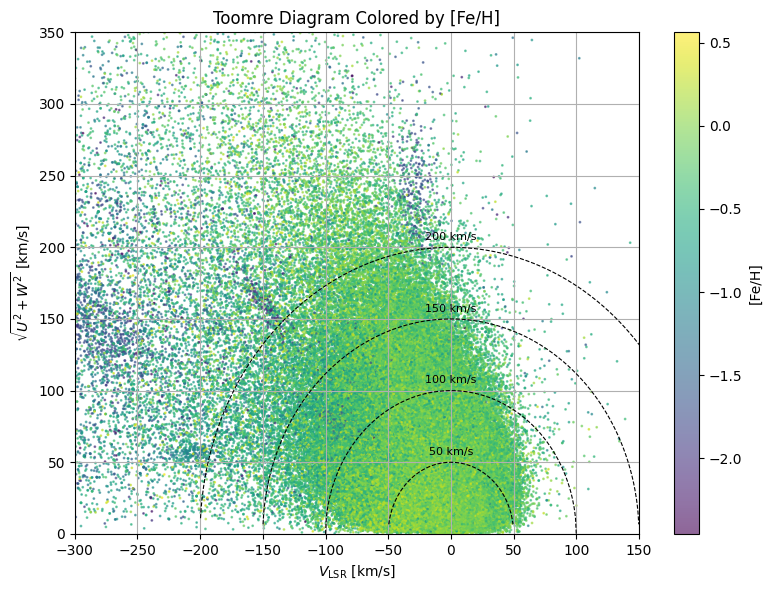

In [ ]:
from astropy.coordinates import SkyCoord, Galactocentric
import astropy.units as u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar los datos
df = pd.read_csv("clean.csv")

# Filtrar filas con datos completos necesarios
cols_needed = ['RA', 'DEC', 'GAIAEDR3_PMRA', 'GAIAEDR3_PMDEC',
               'distance_pc', 'VHELIO_AVG', 'X_gal', 'Y_gal', 'Z_gal', 'FE_H']
df = df.dropna(subset=cols_needed).copy()

# Calcular Z_abs y R_GC
df['Z_abs'] = np.abs(df['Z_gal'])
df['R_GC'] = np.sqrt(df['X_gal']**2 + df['Y_gal']**2)

# Calcular velocidades espaciales U, V, W
c_icrs = SkyCoord(
    ra=df['RA'].values * u.deg,
    dec=df['DEC'].values * u.deg,
    distance=df['distance_pc'].values * u.pc,
    pm_ra_cosdec=df['GAIAEDR3_PMRA'].values * u.mas/u.yr,
    pm_dec=df['GAIAEDR3_PMDEC'].values * u.mas/u.yr,
    radial_velocity=df['VHELIO_AVG'].values * u.km/u.s,
    frame='icrs'
)

c_galcen = c_icrs.transform_to(Galactocentric())
uvw = c_galcen.velocity.d_xyz.to(u.km/u.s)
df['U'] = uvw[0].value
df['V'] = uvw[1].value
df['W'] = uvw[2].value
df['V_perp'] = np.sqrt(df['U']**2 + df['W']**2)

# Corregir al LSR
V_sun = 232  # km/s
df['V_LSR'] = df['V'] - V_sun

# Gráfico Toomre coloreado por metalicidad
plt.figure(figsize=(8, 6))
sc = plt.scatter(df['V_LSR'], df['V_perp'], c=df['FE_H'], cmap='viridis', s=1, alpha=0.6)
plt.xlabel(r'$V_{\mathrm{LSR}}$ [km/s]')
plt.ylabel(r'$\sqrt{U^2 + W^2}$ [km/s]')
plt.title('Toomre Diagram Colored by [Fe/H]')
cbar = plt.colorbar(sc)
cbar.set_label('[Fe/H]')

# Isolíneas de energía cinemática
for v_tot in [50, 100, 150, 200]:
    v = np.linspace(-300, 300, 1000)
    v_perp = np.sqrt(v_tot**2 - v**2)
    v_perp = np.where(np.isreal(v_perp), v_perp, np.nan)
    plt.plot(v, v_perp, 'k--', linewidth=0.8)
    plt.text(0, v_tot + 5, f'{v_tot} km/s', ha='center', fontsize=8)

plt.xlim(-300, 150)
plt.ylim(0, 350)
plt.grid(True)
plt.tight_layout()
plt.show()


<ipython-input-27-ba61a1dc9705>:8: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")


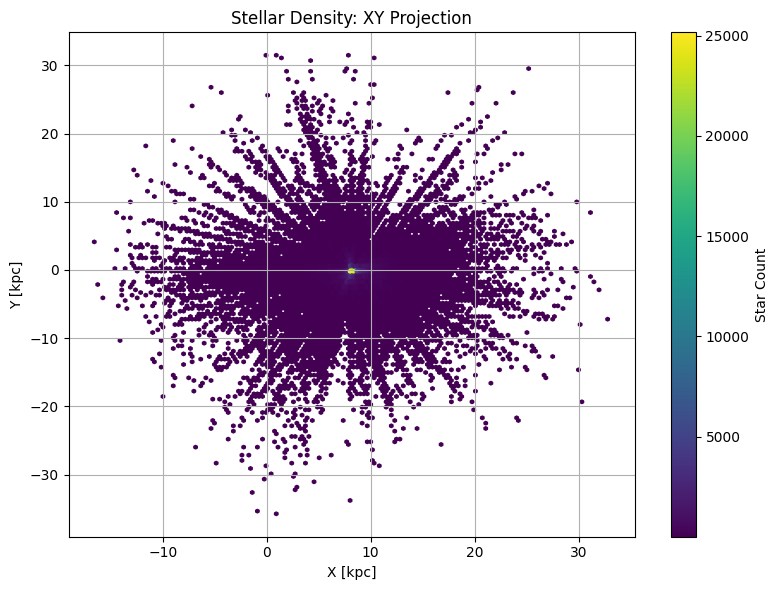

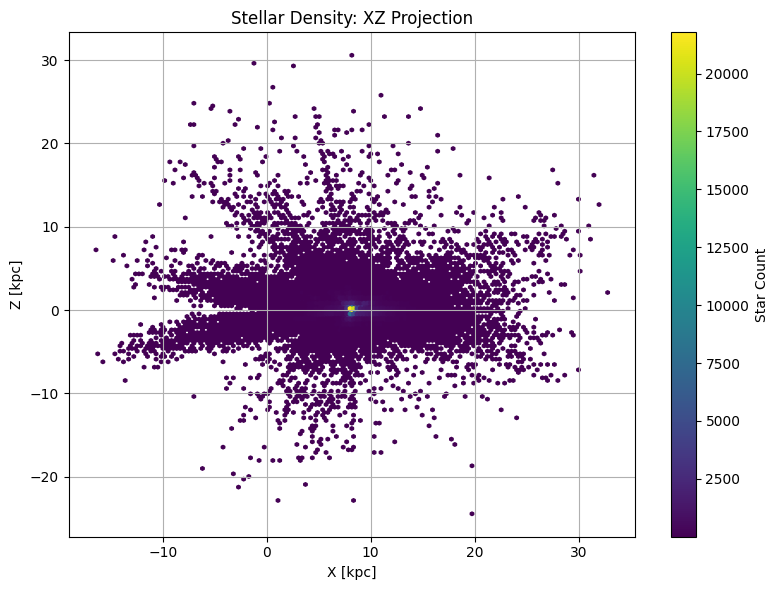

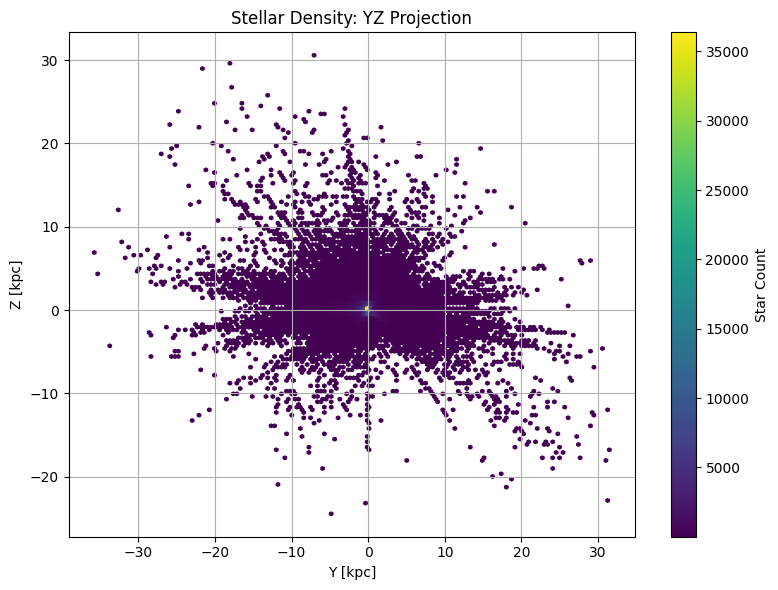

In [ ]:
from astropy.coordinates import SkyCoord, Galactocentric
import astropy.units as u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar datos
df = pd.read_csv("clean.csv")

# Asegúrate de que las columnas necesarias existan
cols_needed = ['RA', 'DEC', 'GAIAEDR3_PMRA', 'GAIAEDR3_PMDEC',
               'distance_pc', 'VHELIO_AVG', 'X_gal', 'Y_gal', 'Z_gal']
df = df.dropna(subset=cols_needed).copy()

# Calcular velocidades U, V, W usando VHELIO (ya en el LSR)
c_icrs = SkyCoord(
    ra=df['RA'].values * u.deg,
    dec=df['DEC'].values * u.deg,
    distance=df['distance_pc'].values * u.pc,
    pm_ra_cosdec=df['GAIAEDR3_PMRA'].values * u.mas/u.yr,
    pm_dec=df['GAIAEDR3_PMDEC'].values * u.mas/u.yr,
    radial_velocity=df['VHELIO_AVG'].values * u.km/u.s,
    frame='icrs'
)

# Convertir a sistema galactocéntrico
c_galcen = c_icrs.transform_to(Galactocentric())
uvw = c_galcen.velocity.d_xyz.to(u.km/u.s)

# Añadir a DataFrame
df['U'] = uvw[0].value
df['V'] = uvw[1].value
df['W'] = uvw[2].value

# ========================
# MAPAS DE DENSIDAD 2D
# ========================

def plot_hexbin(x, y, xlabel, ylabel, title):
    plt.figure(figsize=(8, 6))
    hb = plt.hexbin(x, y, gridsize=150, cmap='viridis', mincnt=1)
    cb = plt.colorbar(hb)
    cb.set_label('Star Count')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# XY projection
plot_hexbin(df['X_gal'], df['Y_gal'], 'X [kpc]', 'Y [kpc]', 'Stellar Density: XY Projection')

# XZ projection
plot_hexbin(df['X_gal'], df['Z_gal'], 'X [kpc]', 'Z [kpc]', 'Stellar Density: XZ Projection')

# YZ projection
plot_hexbin(df['Y_gal'], df['Z_gal'], 'Y [kpc]', 'Z [kpc]', 'Stellar Density: YZ Projection')


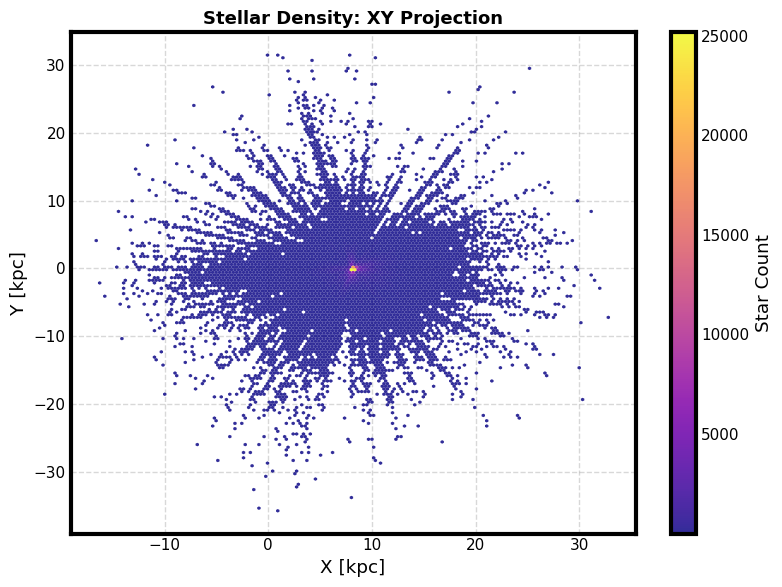

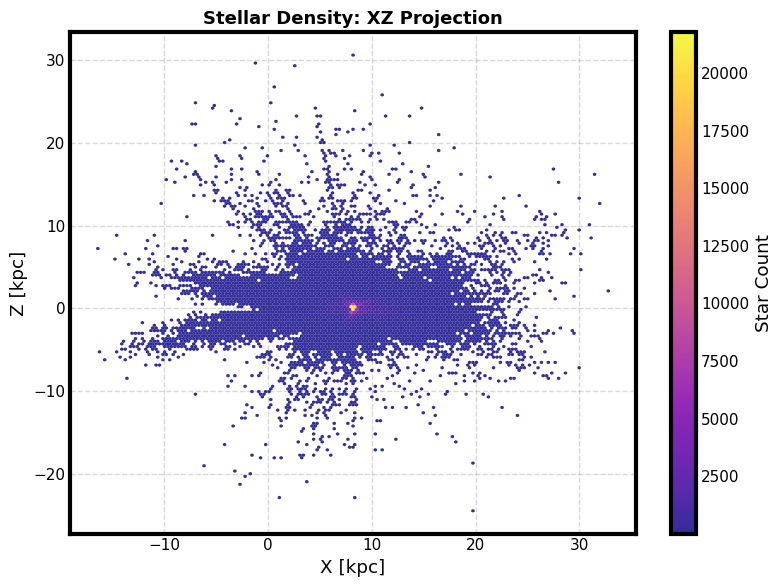

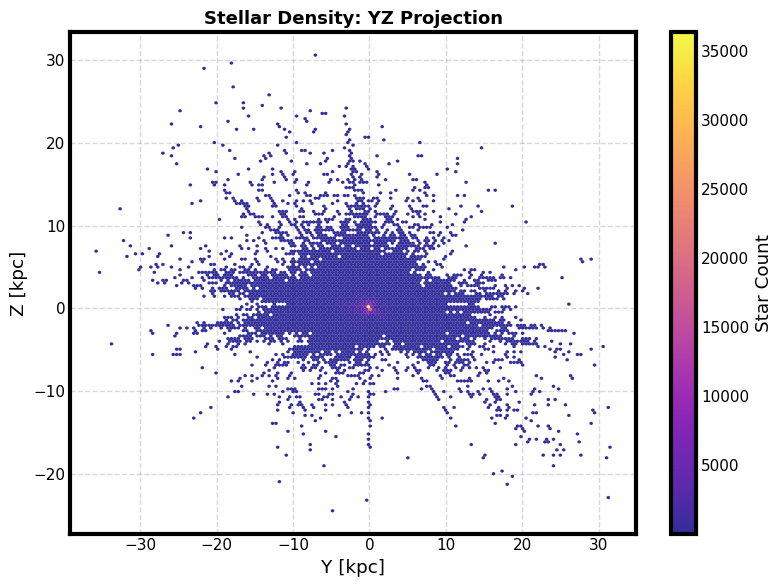

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

#estilo "fivethirtyeight"
plt.style.use('fivethirtyeight')
mpl.rcParams.update({
    'axes.facecolor': 'white',
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'figure.facecolor': 'white',
    'grid.color': 'gray',
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'axes.grid': True,
    'font.size': 11,
})

# Función para graficar mapas hexagonales de densidad
def plot_hexbin_bauhaus(x, y, xlabel, ylabel, title):
    plt.figure(figsize=(8, 6))
    hb = plt.hexbin(x, y, gridsize=150, cmap='plasma', mincnt=1, alpha=0.85, linewidths=0)
    cb = plt.colorbar(hb)
    cb.set_label('Star Count')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title, fontsize=13, weight='bold')
    plt.tight_layout()
    plt.show()

# Graficar proyecciones
plot_hexbin_bauhaus(df['X_gal'], df['Y_gal'], 'X [kpc]', 'Y [kpc]', 'Stellar Density: XY Projection')
plot_hexbin_bauhaus(df['X_gal'], df['Z_gal'], 'X [kpc]', 'Z [kpc]', 'Stellar Density: XZ Projection')
plot_hexbin_bauhaus(df['Y_gal'], df['Z_gal'], 'Y [kpc]', 'Z [kpc]', 'Stellar Density: YZ Projection')


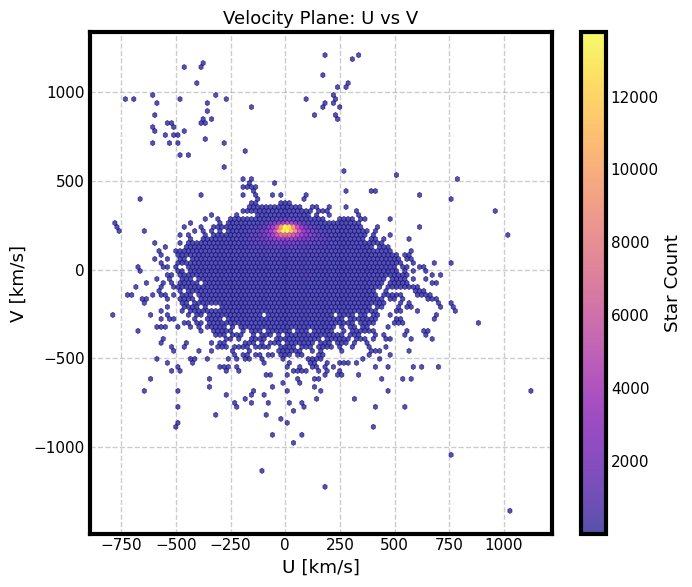

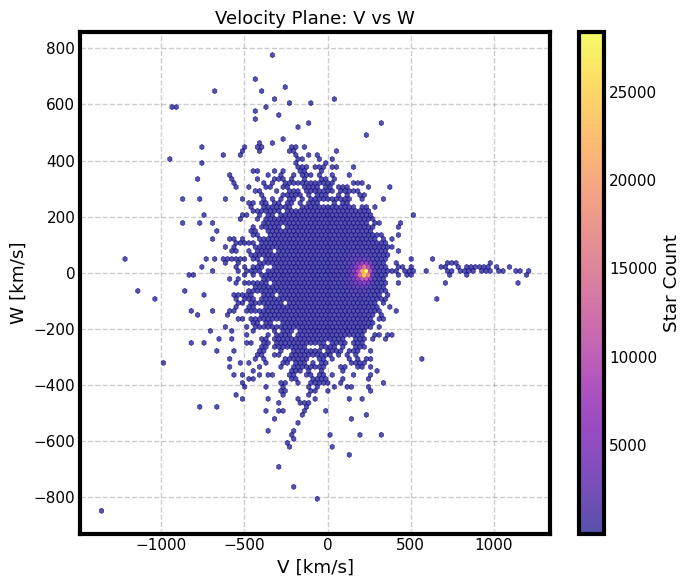

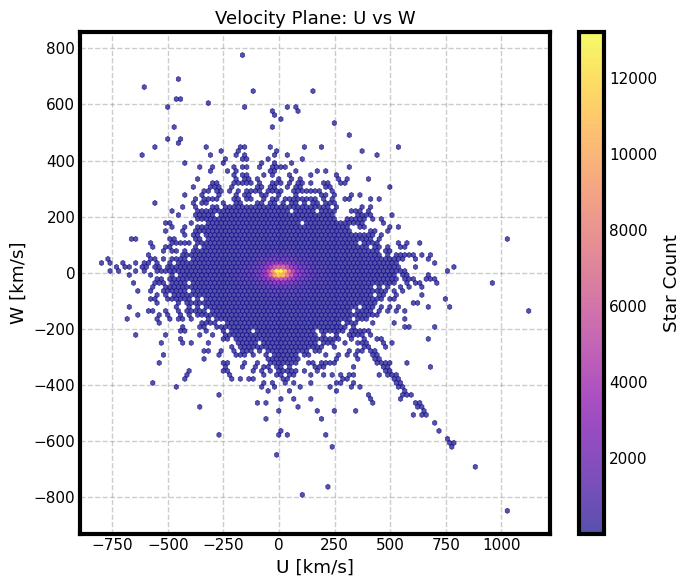

Vertex Deviation Angle (θ): -26.64 degrees


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Scatter plots of velocity projections ===

def plot_velocity_plane(x, y, xlabel, ylabel, title):
    plt.figure(figsize=(7, 6))
    plt.hexbin(x, y, gridsize=100, cmap='plasma', mincnt=1, alpha=0.7)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title, fontsize=13)
    plt.colorbar(label='Star Count')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

# Proyecciones del elipsoide de velocidades
plot_velocity_plane(df['U'], df['V'], 'U [km/s]', 'V [km/s]', 'Velocity Plane: U vs V')
plot_velocity_plane(df['V'], df['W'], 'V [km/s]', 'W [km/s]', 'Velocity Plane: V vs W')
plot_velocity_plane(df['U'], df['W'], 'U [km/s]', 'W [km/s]', 'Velocity Plane: U vs W')


# === 2. Vertex Deviation Estimation ===
# Se calcula el ángulo θ de inclinación del elipsoide en el plano UV

# Extraer datos
U = df['U'].dropna()
V = df['V'].dropna()

# Asegurar dimensiones compatibles
U, V = U.align(V, join='inner')

# Calcular matriz de covarianza
cov_matrix = np.cov(U, V)
sigma_UV = cov_matrix[0, 1]
sigma_U = np.sqrt(cov_matrix[0, 0])
sigma_V = np.sqrt(cov_matrix[1, 1])

# Calcular ángulo de desviación del vértice
theta_rad = 0.5 * np.arctan2(2 * sigma_UV, (sigma_U**2 - sigma_V**2))
theta_deg = np.degrees(theta_rad)

print(f"Vertex Deviation Angle (θ): {theta_deg:.2f} degrees")


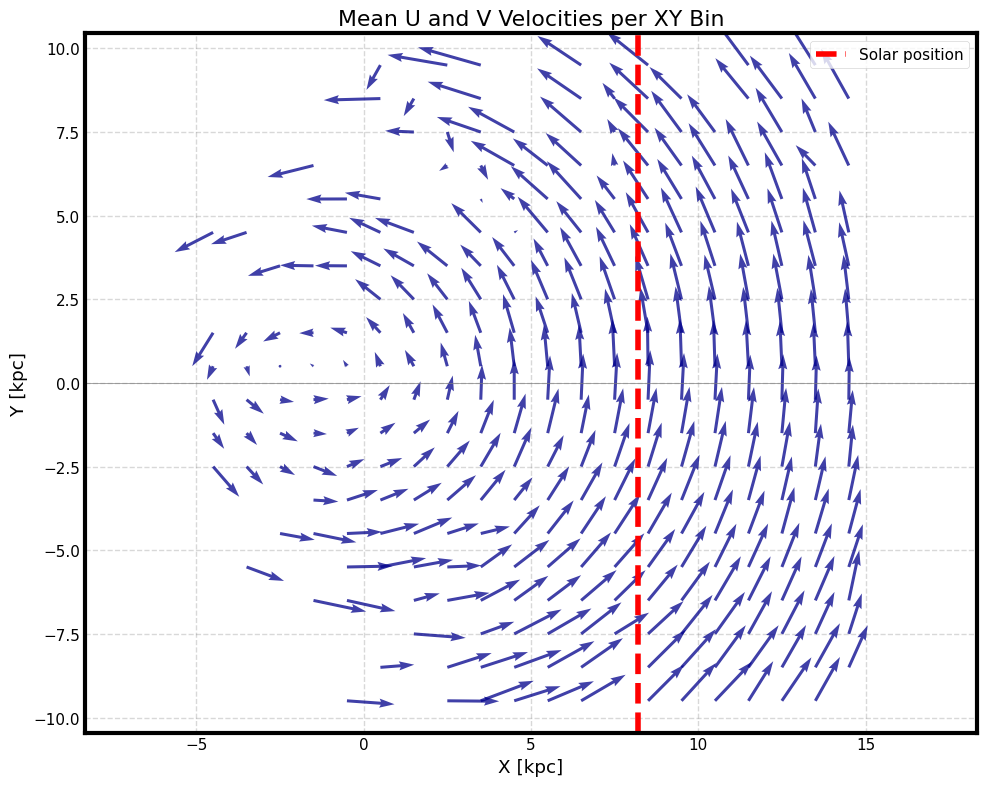

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tamaño del bin (kpc)
bin_size = 1.0

# Rango del mapa XY
x_min, x_max = -5, 15
y_min, y_max = -10, 10

# Crear bins
x_bins = np.arange(x_min, x_max + bin_size, bin_size)
y_bins = np.arange(y_min, y_max + bin_size, bin_size)

# Crear arrays de resultados
X_centers = []
Y_centers = []
U_mean = []
V_mean = []

# Loop sobre la grilla
for i in range(len(x_bins) - 1):
    for j in range(len(y_bins) - 1):
        x0, x1 = x_bins[i], x_bins[i + 1]
        y0, y1 = y_bins[j], y_bins[j + 1]

        # Selección de estrellas en el bin
        mask = (df['X_gal'] >= x0) & (df['X_gal'] < x1) & \
               (df['Y_gal'] >= y0) & (df['Y_gal'] < y1)
        subset = df[mask]

        if len(subset) > 20:  # umbral mínimo para estadísticas confiables
            X_centers.append((x0 + x1) / 2)
            Y_centers.append((y0 + y1) / 2)
            U_mean.append(np.mean(subset['U']))
            V_mean.append(np.mean(subset['V']))

# Convertir a arrays
X_centers = np.array(X_centers)
Y_centers = np.array(Y_centers)
U_mean = np.array(U_mean)
V_mean = np.array(V_mean)

# Plot de vectores U y V
plt.figure(figsize=(10, 8))
plt.quiver(X_centers, Y_centers, U_mean, V_mean, angles='xy', scale_units='xy', scale=150, color='darkblue', alpha=0.75)
plt.xlabel('X [kpc]')
plt.ylabel('Y [kpc]')
plt.title('Mean U and V Velocities per XY Bin')
plt.grid(True, linestyle='--', alpha=0.3)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(8.2, color='red', linestyle='--', label='Solar position')
plt.legend()
plt.axis('equal')
plt.tight_layout()
plt.show()


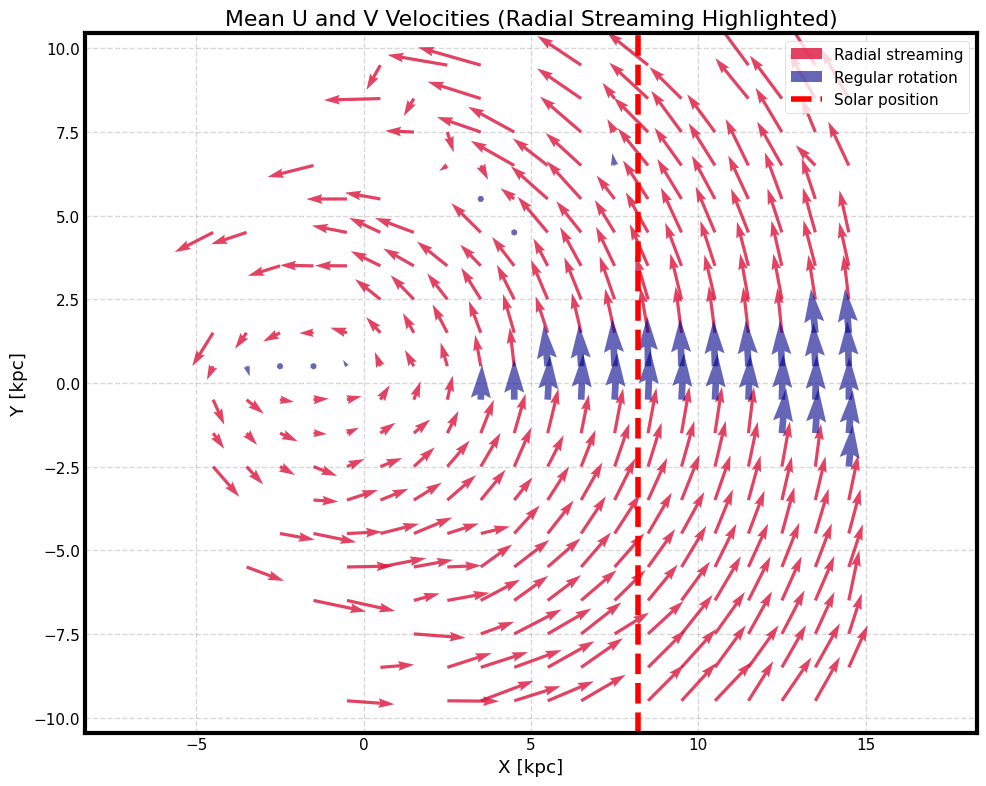

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Umbral para definir "streaming" significativo (en km/s)
streaming_threshold = 20

# Convertir listas a arrays
X_centers = np.array(X_centers)
Y_centers = np.array(Y_centers)
U_mean = np.array(U_mean)
V_mean = np.array(V_mean)

# Separar en flechas con y sin streaming radial
mask_streaming = np.abs(U_mean) > streaming_threshold

# Plot
plt.figure(figsize=(10, 8))

# Flechas con flujo radial fuerte (streaming)
plt.quiver(X_centers[mask_streaming], Y_centers[mask_streaming],
           U_mean[mask_streaming], V_mean[mask_streaming],
           angles='xy', scale_units='xy', scale=150,
           color='crimson', label='Radial streaming', alpha=0.8)

# Flechas normales
plt.quiver(X_centers[~mask_streaming], Y_centers[~mask_streaming],
           U_mean[~mask_streaming], V_mean[~mask_streaming],
           angles='xy', scale_units='xy', scale=150,
           color='darkblue', alpha=0.6, label='Regular rotation')

# Ejes y leyenda
plt.axvline(8.2, color='red', linestyle='--', label='Solar position')
plt.xlabel('X [kpc]')
plt.ylabel('Y [kpc]')
plt.title('Mean U and V Velocities (Radial Streaming Highlighted)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.axis('equal')
plt.tight_layout()
plt.show()


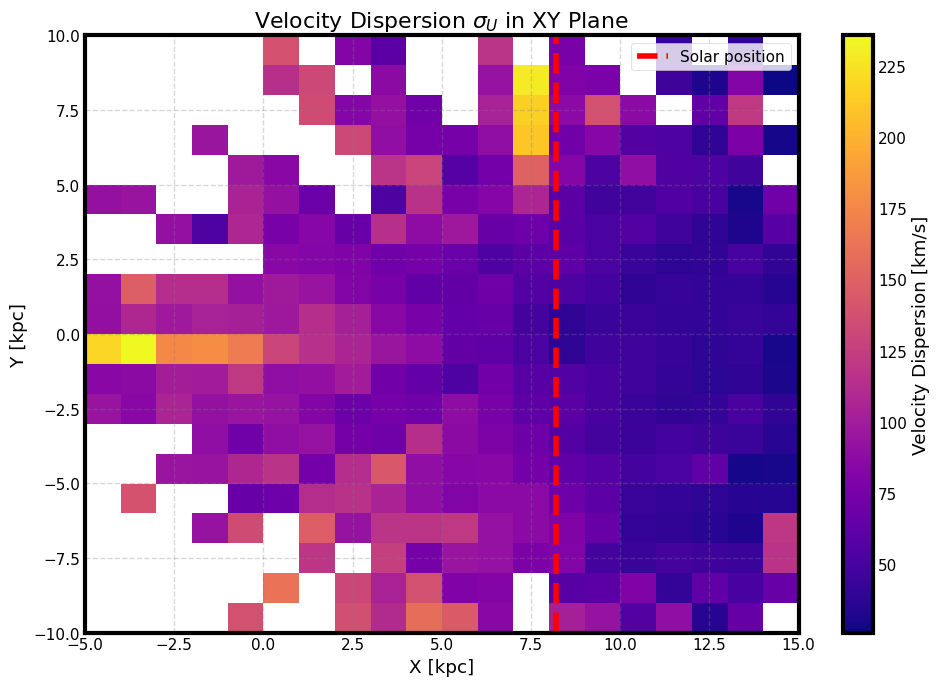

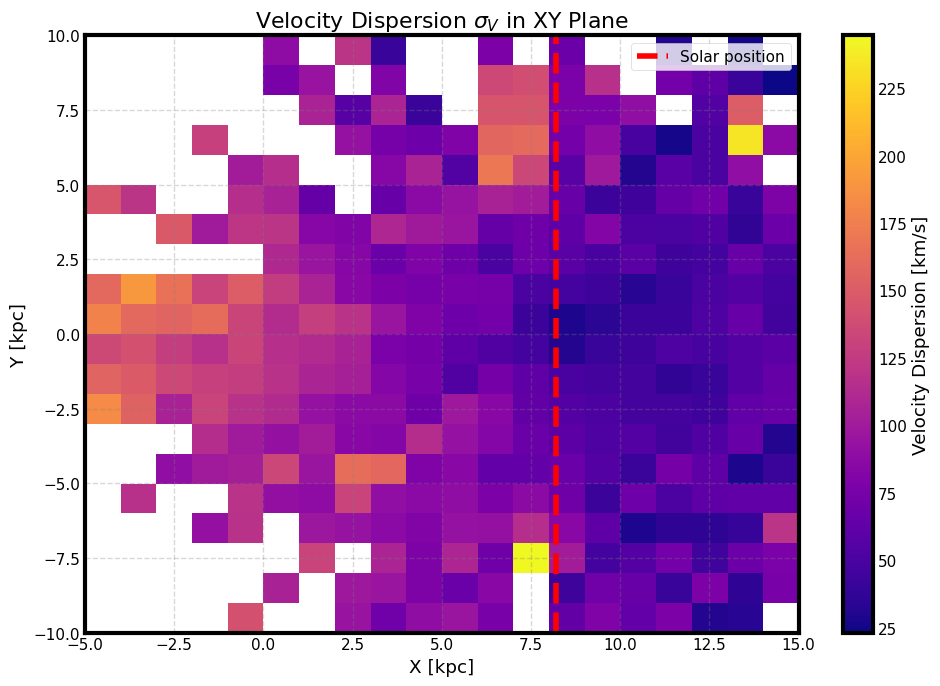

In [ ]:
# Crear grillas vacías para dispersión
grid_sigma_U = np.full((len(y_bins)-1, len(x_bins)-1), np.nan)
grid_sigma_V = np.full((len(y_bins)-1, len(x_bins)-1), np.nan)

# Rellenar cada celda de la grilla con la dispersión local
for i in range(len(x_bins) - 1):
    for j in range(len(y_bins) - 1):
        x0, x1 = x_bins[i], x_bins[i + 1]
        y0, y1 = y_bins[j], y_bins[j + 1]

        mask = (df['X_gal'] >= x0) & (df['X_gal'] < x1) & \
               (df['Y_gal'] >= y0) & (df['Y_gal'] < y1)
        subset = df[mask]

        if len(subset) > 20:
            grid_sigma_U[j, i] = np.std(subset['U'])
            grid_sigma_V[j, i] = np.std(subset['V'])

# Función de graficado para sigma
def plot_sigma_grid(grid, title, cmap='plasma'):
    plt.figure(figsize=(10, 7))
    im = plt.imshow(grid, origin='lower', cmap=cmap,
                    extent=[x_min, x_max, y_min, y_max],
                    aspect='auto')
    plt.colorbar(im, label='Velocity Dispersion [km/s]')
    plt.xlabel('X [kpc]')
    plt.ylabel('Y [kpc]')
    plt.title(title)
    plt.axvline(8.2, color='red', linestyle='--', label='Solar position')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# Graficar mapas de dispersión
plot_sigma_grid(grid_sigma_U, 'Velocity Dispersion $\sigma_U$ in XY Plane')
plot_sigma_grid(grid_sigma_V, 'Velocity Dispersion $\sigma_V$ in XY Plane')


28157 stars within 250 pc of the Sun.


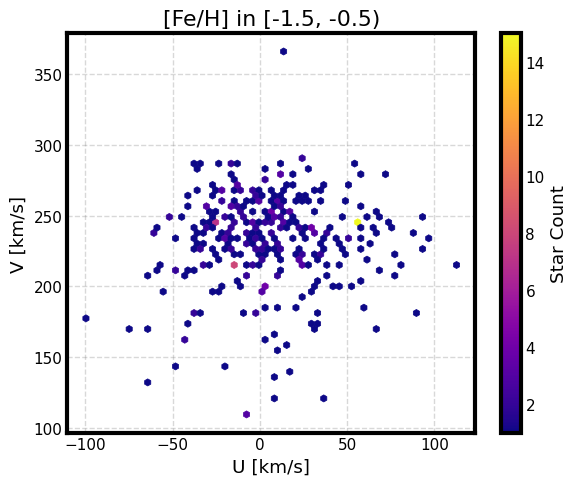

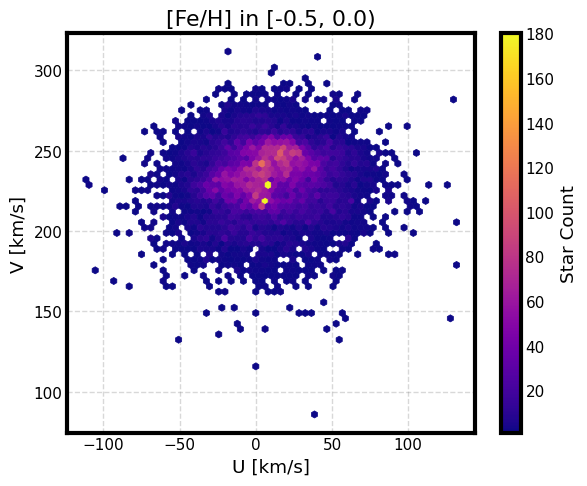

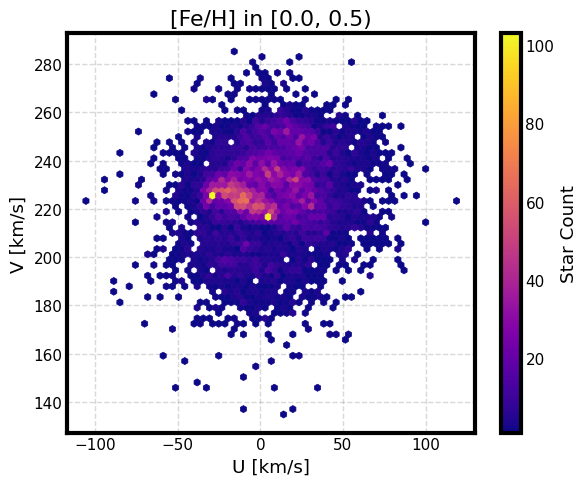

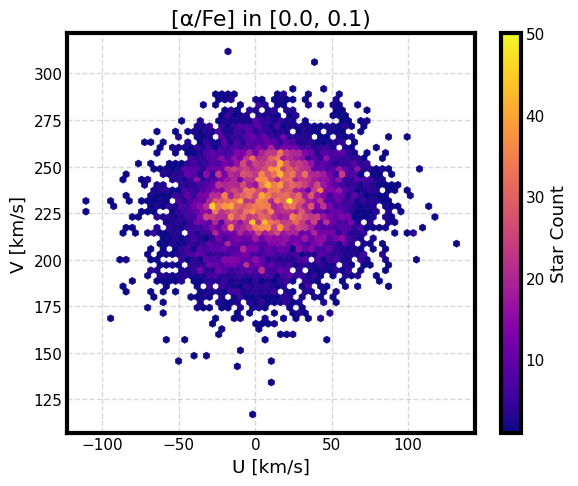

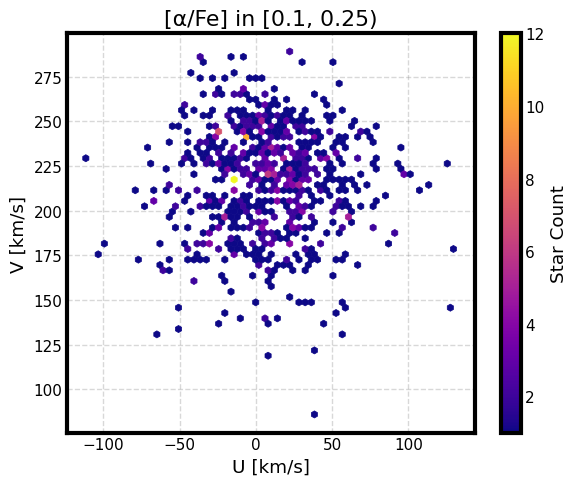

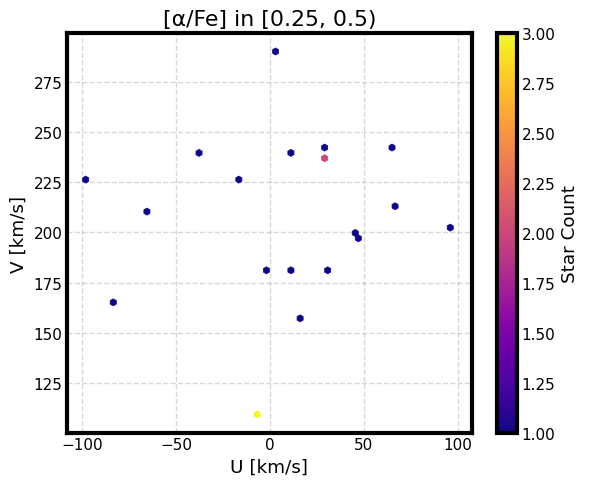

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Selección de estrellas cercanas al Sol (radio de 250 pc) ---
# Suponiendo que df tiene columnas X_gal, Y_gal, Z_gal
df['distance_to_sun'] = np.sqrt((df['X_gal'] - 8.2)**2 + df['Y_gal']**2 + df['Z_gal']**2)
df_local = df[df['distance_to_sun'] <= 0.25].copy()

# Confirmar cuántas hay
print(f"{len(df_local)} stars within 250 pc of the Sun.")

# --- 2. Definir bins de metalicidad y alfa/Fe ---
# Rango de cortes para [Fe/H]
feh_bins = [(-1.5, -0.5), (-0.5, 0.0), (0.0, 0.5)]
# Rango de cortes para [alpha/Fe] (puedes ajustar si es necesario)
alpha_bins = [(0.0, 0.1), (0.1, 0.25), (0.25, 0.5)]

# --- 3. Función para graficar UV para un corte dado ---
def plot_uv_plane(subset, title):
    plt.figure(figsize=(6, 5))
    plt.hexbin(subset['U'], subset['V'], gridsize=60, cmap='plasma', mincnt=1)
    plt.xlabel('U [km/s]')
    plt.ylabel('V [km/s]')
    plt.title(title)
    plt.colorbar(label='Star Count')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- 4. Graficar cortes por [Fe/H] ---
for feh_min, feh_max in feh_bins:
    mask = (df_local['FE_H'] >= feh_min) & (df_local['FE_H'] < feh_max)
    subset = df_local[mask]
    plot_uv_plane(subset, f'[Fe/H] in [{feh_min}, {feh_max})')

# --- 5. Graficar cortes por [alpha/Fe] ---
if 'ALPHA_M' in df_local.columns:
    for a_min, a_max in alpha_bins:
        mask = (df_local['ALPHA_M'] >= a_min) & (df_local['ALPHA_M'] < a_max)
        subset = df_local[mask]
        plot_uv_plane(subset, f'[α/Fe] in [{a_min}, {a_max})')
else:
    print("Column 'ALPHA_M' not found in dataframe.")


16 kinematic groups identified


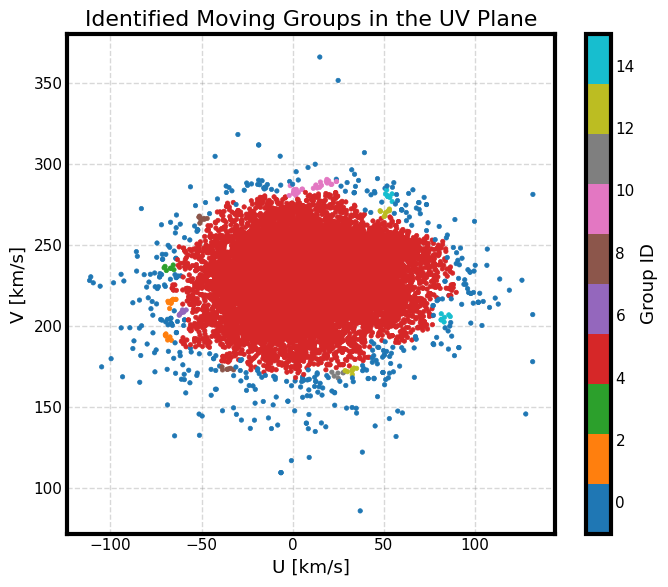

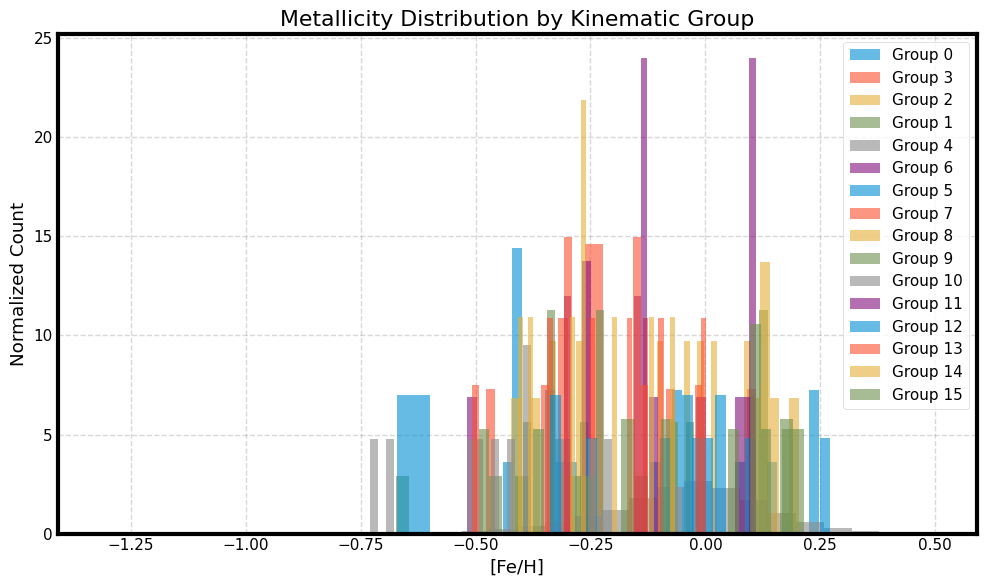

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# --- Usamos las estrellas dentro de 250 pc ---
X = df_local[['U', 'V']].dropna().values  # UV plane

# --- DBSCAN para identificar grupos cinemáticos ---
db = DBSCAN(eps=3.5, min_samples=7).fit(X)
labels = db.labels_

# Añadir etiquetas al dataframe
df_local = df_local.iloc[X[:, 0].argsort()]  # para alinear si se hizo dropna()
df_local = df_local.reset_index(drop=True)
df_local['group_label'] = labels

# --- Número de grupos encontrados ---
n_groups = len(set(labels)) - (1 if -1 in labels else 0)
print(f"{n_groups} kinematic groups identified")

# --- Graficar UV con etiquetas de grupo ---
plt.figure(figsize=(7, 6))
scatter = plt.scatter(df_local['U'], df_local['V'], c=df_local['group_label'], cmap='tab10', s=10)
plt.xlabel('U [km/s]')
plt.ylabel('V [km/s]')
plt.title('Identified Moving Groups in the UV Plane')
plt.grid(True, linestyle='--', alpha=0.3)
plt.colorbar(scatter, label='Group ID')
plt.tight_layout()
plt.show()

# --- Graficar distribución de [Fe/H] por grupo ---
# Filtrar grupos válidos
valid_groups = df_local[df_local['group_label'] != -1]['group_label'].unique()

plt.figure(figsize=(10, 6))
for g in valid_groups:
    feh = df_local[df_local['group_label'] == g]['FE_H']
    plt.hist(feh, bins=30, alpha=0.6, label=f'Group {g}', density=True)

plt.xlabel('[Fe/H]')
plt.ylabel('Normalized Count')
plt.title('Metallicity Distribution by Kinematic Group')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


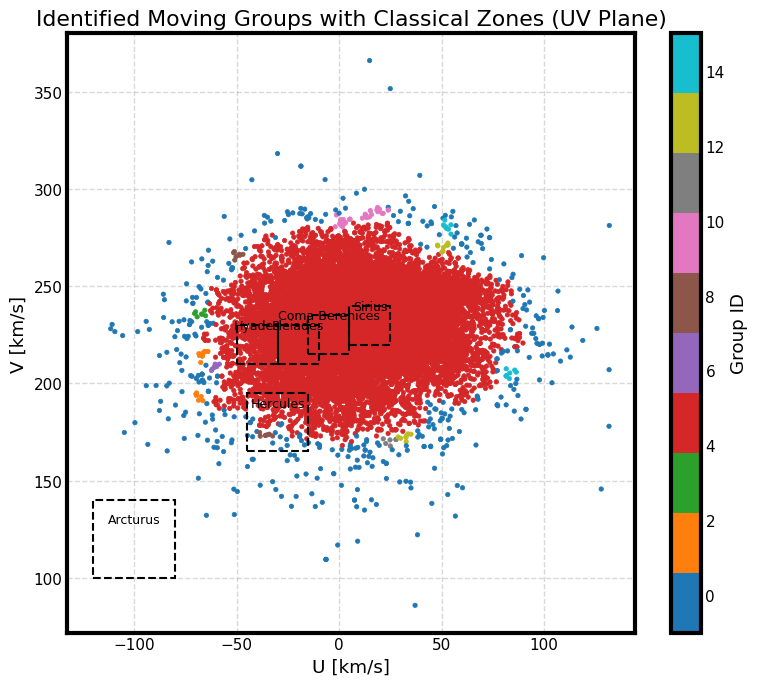

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Crear la figura y eje
fig, ax = plt.subplots(figsize=(8, 7))

# Gráfico original de DBSCAN con color por grupo
scatter = ax.scatter(df_local['U'], df_local['V'],
                     c=df_local['group_label'], cmap='tab10', s=10)
plt.colorbar(scatter, ax=ax, label='Group ID')

# Definición de zonas clásicas: (U_center, V_center, width_U, height_V)
groups = {
    "Hyades": (-40, 220, 20, 20),
    "Pleiades": (-20, 220, 20, 20),
    "Coma Berenices": (-5, 225, 20, 20),
    "Sirius": (15, 230, 20, 20),
    "Hercules": (-30, 180, 30, 30),
    "Arcturus": (-100, 120, 40, 40),
}

# Añadir rectángulos de los grupos clásicos
for name, (u, v, w, h) in groups.items():
    rect = patches.Rectangle((u - w / 2, v - h / 2), w, h,
                             linewidth=1.5, edgecolor='black',
                             facecolor='none', linestyle='--')
    ax.add_patch(rect)
    ax.text(u, v + 8, name, fontsize=9, ha='center', color='black')

# Etiquetas y ajustes
ax.set_xlabel('U [km/s]')
ax.set_ylabel('V [km/s]')
ax.set_title('Identified Moving Groups with Classical Zones (UV Plane)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


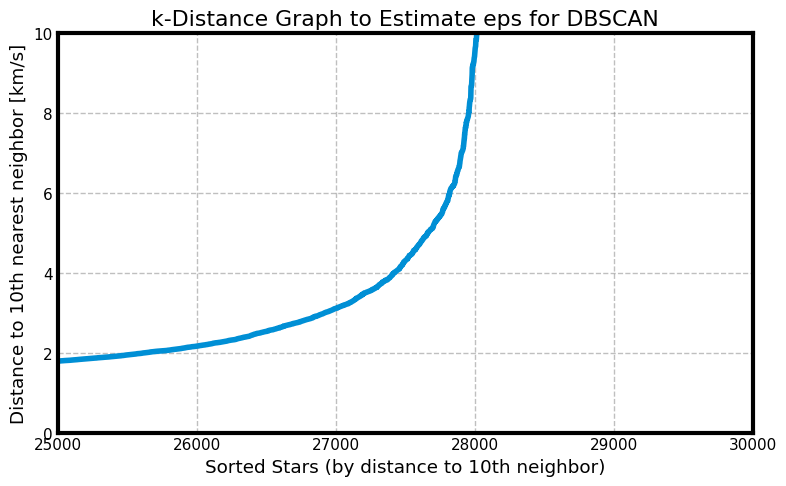

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Seleccionar el espacio de velocidades (ej. U y V)
X = df_local[['U', 'V']].dropna().values

# Número de vecinos (k = min_samples) → usualmente 5–10
k = 10
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X)

# Obtener las distancias al k-ésimo vecino más cercano
distances, indices = neighbors_fit.kneighbors(X)

# Ordenar las distancias (solo la distancia al k-ésimo vecino)
k_distances = np.sort(distances[:, k-1])

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel(f"Sorted Stars (by distance to {k}th neighbor)")
plt.ylabel(f"Distance to {k}th nearest neighbor [km/s]")
plt.title("k-Distance Graph to Estimate eps for DBSCAN")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(25000, 30000)
plt.ylim(0, 10)
plt.tight_layout()
plt.show()


<ipython-input-93-06284801c9bf>:14: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")
<ipython-input-93-06284801c9bf>:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rotation_curve = df_filtered.groupby("R_bin")[["R_GC", "V_phi_LSR"]].mean()


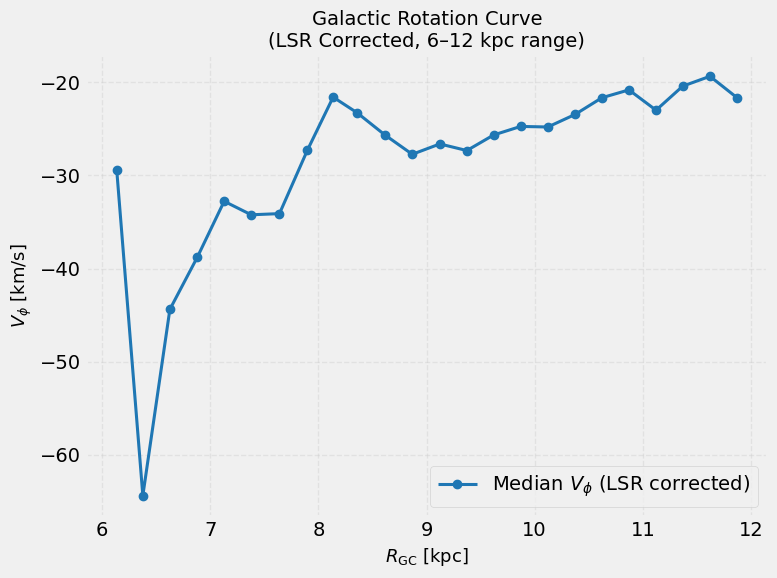

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Estilo
plt.style.use("fivethirtyeight")

# Constantes
k = 4.74047  # mas/año a km/s
R_sun = 8.2  # kpc
U_sun, V_sun, W_sun = 11.1, 12.24, 7.25  # km/s (Schönrich et al. 2010)

# Cargar datos
df = pd.read_csv("clean.csv")

# Conversión de ángulos
ra = np.radians(df["RA"])
dec = np.radians(df["DEC"])
d = df["distance_pc"] / 1000  # pasar de pc a kpc
pmra = df["GAIAEDR3_PMRA"]
pmdec = df["GAIAEDR3_PMDEC"]
vrad = df["VHELIO_AVG"]

# Matriz de transformación a galáctico
A_gal = np.array([
    [-0.05487556, -0.87343709, -0.48383502],
    [ 0.49410943, -0.44482963,  0.74698224],
    [-0.86766615, -0.19807637,  0.45598378]
])

# Velocidades en coordenadas ecuatoriales
mu_ra_kms = k * pmra * d
mu_dec_kms = k * pmdec * d

vx = vrad * np.cos(dec) * np.cos(ra) - mu_ra_kms * np.sin(ra) - mu_dec_kms * np.cos(ra) * np.sin(dec)
vy = vrad * np.cos(dec) * np.sin(ra) + mu_ra_kms * np.cos(ra) - mu_dec_kms * np.sin(ra) * np.sin(dec)
vz = vrad * np.sin(dec) + mu_dec_kms * np.cos(dec)

v_eq = np.vstack((vx, vy, vz))
v_gal = A_gal @ v_eq

# Corregir por el movimiento solar
U = v_gal[0] + U_sun
V = v_gal[1] + V_sun
W = v_gal[2] + W_sun

# Asignar a DataFrame
df["U"], df["V"], df["W"] = U, V, W

# Ángulo azimutal galactocéntrico
df["phi"] = np.arctan2(df["Y_gal"], df["X_gal"])

# Velocidad tangencial en coordenadas cilíndricas
df["V_phi"] = -df["U"] * np.sin(df["phi"]) + df["V"] * np.cos(df["phi"])

# ✅ Corregir por el LSR (restar 12.24 km/s de rotación solar)
df["V_phi_LSR"] = df["V_phi"] - 12.24

# Filtrar estrellas entre 6 y 12 kpc
df_filtered = df[(df["R_GC"] >= 6) & (df["R_GC"] <= 12)].copy()

# Bin radial
bins = np.linspace(6, 12, 25)
df_filtered["R_bin"] = pd.cut(df_filtered["R_GC"], bins=bins)
rotation_curve = df_filtered.groupby("R_bin")[["R_GC", "V_phi_LSR"]].mean()

# Gráfico estilizado
plt.figure(figsize=(8, 6))
plt.plot(rotation_curve["R_GC"], rotation_curve["V_phi_LSR"],
         marker="o", linestyle="-", linewidth=2.2, color="#1f77b4", label="Median $V_\\phi$ (LSR corrected)")

plt.xlabel("$R_{\\rm GC}$ [kpc]", fontsize=13)
plt.ylabel("$V_{\\phi}$ [km/s]", fontsize=13)
plt.title("Galactic Rotation Curve\n(LSR Corrected, 6–12 kpc range)", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


<ipython-input-2-51626fa4de14>:14: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")
<ipython-input-2-51626fa4de14>:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rotation_curve = df_filtered.groupby("R_bin")[["R_GC", "V_phi_LSR"]].mean()


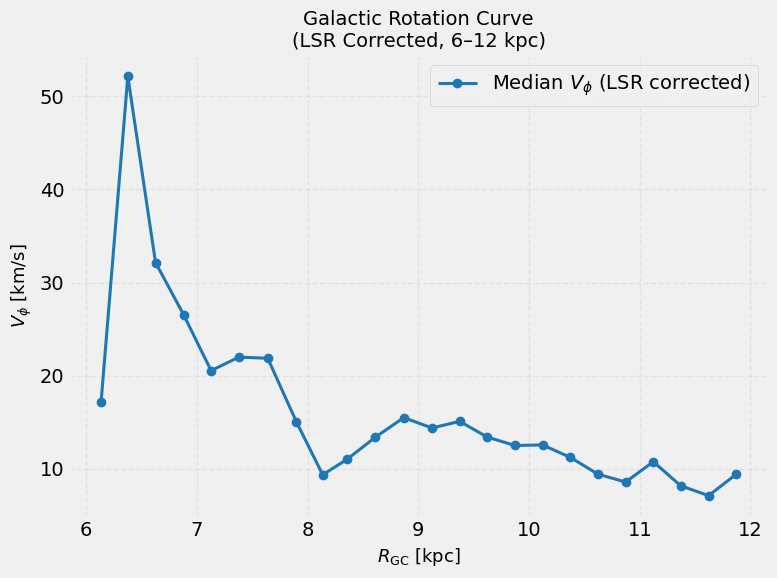

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Estilo
plt.style.use("fivethirtyeight")

# Constantes
k = 4.74047  # mas/año a km/s
R_sun = 8.2  # kpc
U_sun, V_sun, W_sun = 11.1, 12.24, 7.25  # km/s (Schönrich et al. 2010)

# Cargar datos
df = pd.read_csv("clean.csv")

# Conversión de coordenadas
ra = np.radians(df["RA"])
dec = np.radians(df["DEC"])
d = df["distance_pc"] / 1000  # pasar de pc a kpc
pmra = df["GAIAEDR3_PMRA"]
pmdec = df["GAIAEDR3_PMDEC"]
vrad = df["VHELIO_AVG"]

# Matriz de transformación a galáctico
A_gal = np.array([
    [-0.05487556, -0.87343709, -0.48383502],
    [ 0.49410943, -0.44482963,  0.74698224],
    [-0.86766615, -0.19807637,  0.45598378]
])

# Velocidades ecuatoriales
mu_ra_kms = k * pmra * d
mu_dec_kms = k * pmdec * d

vx = vrad * np.cos(dec) * np.cos(ra) - mu_ra_kms * np.sin(ra) - mu_dec_kms * np.cos(ra) * np.sin(dec)
vy = vrad * np.cos(dec) * np.sin(ra) + mu_ra_kms * np.cos(ra) - mu_dec_kms * np.sin(ra) * np.sin(dec)
vz = vrad * np.sin(dec) + mu_dec_kms * np.cos(dec)

v_eq = np.vstack((vx, vy, vz))
v_gal = A_gal @ v_eq

# Corregir por el movimiento solar
U = v_gal[0] + U_sun
V = v_gal[1] + V_sun
W = v_gal[2] + W_sun

# Asignar a DataFrame
df["U"], df["V"], df["W"] = U, V, W

# Ángulo azimutal galactocéntrico
df["phi"] = np.arctan2(df["Y_gal"], df["X_gal"])

#  V_phi positivo
df["V_phi"] = df["U"] * np.sin(df["phi"]) - df["V"] * np.cos(df["phi"])

# Corregir por el LSR
df["V_phi_LSR"] = df["V_phi"] - 12.24

# Filtrar estrellas entre 6 y 12 kpc
df_filtered = df[(df["R_GC"] >= 6) & (df["R_GC"] <= 12)].copy()

# Binning radial
bins = np.linspace(6, 12, 25)
df_filtered["R_bin"] = pd.cut(df_filtered["R_GC"], bins=bins)
rotation_curve = df_filtered.groupby("R_bin")[["R_GC", "V_phi_LSR"]].mean()

# Gráfico estilizado
plt.figure(figsize=(8, 6))
plt.plot(rotation_curve["R_GC"], rotation_curve["V_phi_LSR"],
         marker="o", linestyle="-", linewidth=2.2, color="#1f77b4", label="Median $V_\\phi$ (LSR corrected)")

plt.xlabel("$R_{\\rm GC}$ [kpc]", fontsize=13)
plt.ylabel("$V_{\\phi}$ [km/s]", fontsize=13)
plt.title("Galactic Rotation Curve\n(LSR Corrected, 6–12 kpc)", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


<ipython-input-7-fabad7b730c0>:24: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")


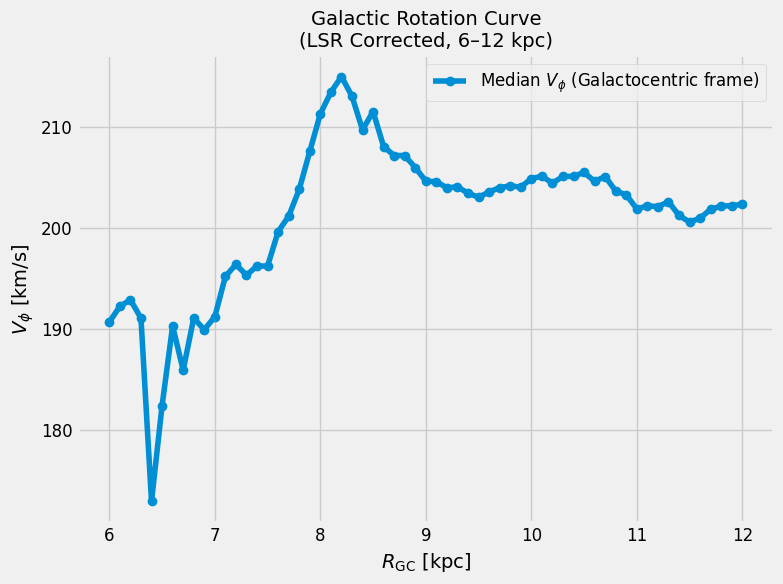

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Estilo
plt.style.use("fivethirtyeight")
rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# Constantes
k = 4.74047  # mas/año a km/s
R_sun = 8.2  # kpc
U_sun, V_sun, W_sun = 11.1, 12.24, 7.25  # km/s (Schönrich et al. 2010)

# Cargar datos
df = pd.read_csv("clean.csv")

# Conversión de coordenadas
ra = np.radians(df["RA"])
dec = np.radians(df["DEC"])
d = df["distance_pc"] / 1000  # pasar de pc a kpc
pmra = df["GAIAEDR3_PMRA"]
pmdec = df["GAIAEDR3_PMDEC"]
vrad = df["VHELIO_AVG"]

# Matriz de transformación a galáctico
A_gal = np.array([
    [-0.05487556, -0.87343709, -0.48383502],
    [ 0.49410943, -0.44482963,  0.74698224],
    [-0.86766615, -0.19807637,  0.45598378]
])

# Velocidades ecuatoriales
mu_ra_kms = k * pmra * d
mu_dec_kms = k * pmdec * d

vx = vrad * np.cos(dec) * np.cos(ra) - mu_ra_kms * np.sin(ra) - mu_dec_kms * np.cos(ra) * np.sin(dec)
vy = vrad * np.cos(dec) * np.sin(ra) + mu_ra_kms * np.cos(ra) - mu_dec_kms * np.sin(ra) * np.sin(dec)
vz = vrad * np.sin(dec) + mu_dec_kms * np.cos(dec)

v_eq = np.vstack((vx, vy, vz))
v_gal = A_gal @ v_eq

# Corregir por el movimiento solar
U = v_gal[0] + U_sun
V = v_gal[1] + V_sun
W = v_gal[2] + W_sun

# Asignar a DataFrame
df["U"], df["V"], df["W"] = U, V, W

# Parámetros del LSR
V_LSR = 220  # km/s

# Calcular ángulo galactocéntrico
df["phi"] = np.arctan2(df["Y_gal"], df["X_gal"])

# Calcular V_phi en marco galactocéntrico rotante corregido
df["V_phi"] = -df["U"] * np.sin(df["phi"]) + (df["V"] + V_LSR) * np.cos(df["phi"])

# Selección en el rango 6 < R_GC < 12 kpc
mask = (df["R_GC"] >= 6) & (df["R_GC"] <= 12)
df_sel = df[mask].copy()

# Binear en R_GC y calcular mediana
df_sel["R_bin"] = df_sel["R_GC"].round(1)
median_vphi = df_sel.groupby("R_bin")["V_phi"].median().reset_index()

# Gráfico
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(median_vphi["R_bin"], median_vphi["V_phi"], "-o", label=r"Median $V_\phi$ (Galactocentric frame)")
ax.set_xlabel(r"$R_{\rm GC}$ [kpc]")
ax.set_ylabel(r"$V_\phi$ [km/s]")
ax.set_title("Galactic Rotation Curve\n(LSR Corrected, 6–12 kpc)")
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Constantes
k = 4.74047  # mas/yr to km/s
R_sun = 8.2  # kpc
U_sun, V_sun, W_sun = 11.1, 12.24, 7.25  # km/s (Schönrich et al. 2010)

# Cargar el archivo
df = pd.read_csv("clean.csv")

# Conversión de unidades y coordenadas
ra = np.radians(df["RA"])
dec = np.radians(df["DEC"])
d = df["distance_pc"] / 1000  # pc a kpc
pmra = df["GAIAEDR3_PMRA"]
pmdec = df["GAIAEDR3_PMDEC"]
vrad = df["VHELIO_AVG"]

# Convertir a velocidades ecuatoriales (cartesianas heliocéntricas)
mu_ra_kms = k * pmra * d
mu_dec_kms = k * pmdec * d

vx = vrad * np.cos(dec) * np.cos(ra) - mu_ra_kms * np.sin(ra) - mu_dec_kms * np.cos(ra) * np.sin(dec)
vy = vrad * np.cos(dec) * np.sin(ra) + mu_ra_kms * np.cos(ra) - mu_dec_kms * np.sin(ra) * np.sin(dec)
vz = vrad * np.sin(dec) + mu_dec_kms * np.cos(dec)

# Matriz de rotación a coordenadas galácticas
A_gal = np.array([
    [-0.05487556, -0.87343709, -0.48383502],
    [ 0.49410943, -0.44482963,  0.74698224],
    [-0.86766615, -0.19807637,  0.45598378]
])

v_eq = np.vstack((vx, vy, vz))
v_gal = A_gal @ v_eq

# Velocidades heliocéntricas corregidas por el Sol
U = v_gal[0] + U_sun
V = v_gal[1] + V_sun
W = v_gal[2] + W_sun

# Agregar al DataFrame
df["U"] = U
df["V"] = V
df["W"] = W

# Calcular distancia galactocéntrica a partir de X_gal, Y_gal, Z_gal
df["r_sun"] = np.sqrt((df["X_gal"] - R_sun)**2 + df["Y_gal"]**2 + (df["Z_gal"] - 0.025)**2)

# Filtrar estrellas dentro de 2 kpc del Sol
df_local = df[df["r_sun"] < 2.0].copy()

# Coordenadas relativas al Sol (plano galáctico)
x = df_local["X_gal"].values - R_sun
y = df_local["Y_gal"].values

# Usar directamente las velocidades calculadas
U = df_local["U"].values
V = df_local["V"].values

# Regressions
X_matrix = np.column_stack((x, y))

reg_U = LinearRegression().fit(X_matrix, U)
reg_V = LinearRegression().fit(X_matrix, V)

dU_dx, dU_dy = reg_U.coef_
dV_dx, dV_dy = reg_V.coef_

# Constantes de Oort
A = 0.5 * (dV_dx - dU_dy)
B = -0.5 * (dV_dx + dU_dy)
C = 0.5 * (dU_dx + dV_dy)
K = 0.5 * (dU_dx - dV_dy)

# Resultados
print("Estimated Oort Constants (within 2 kpc of the Sun):")
print(f"A = {A:.2f} km/s/kpc")
print(f"B = {B:.2f} km/s/kpc")
print(f"C = {C:.2f} km/s/kpc")
print(f"K = {K:.2f} km/s/kpc")


<ipython-input-1-2187f964b186>:12: DtypeWarning: Columns (88) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("clean.csv")


Estimated Oort Constants (within 2 kpc of the Sun):
A = 13.23 km/s/kpc
B = 13.39 km/s/kpc
C = 1.38 km/s/kpc
K = 0.06 km/s/kpc


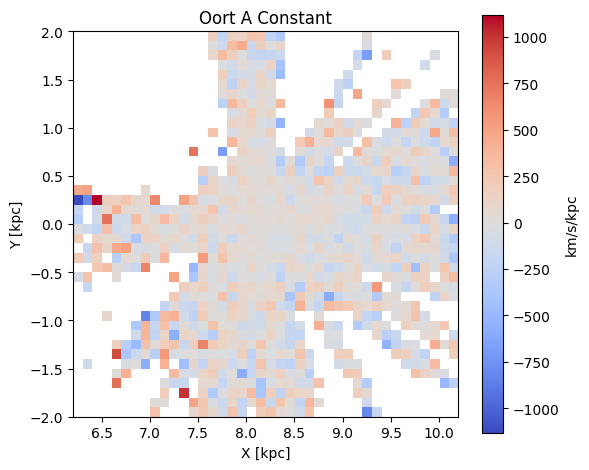

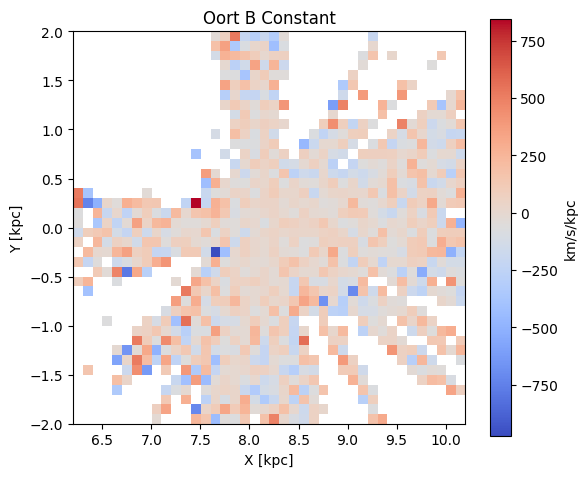

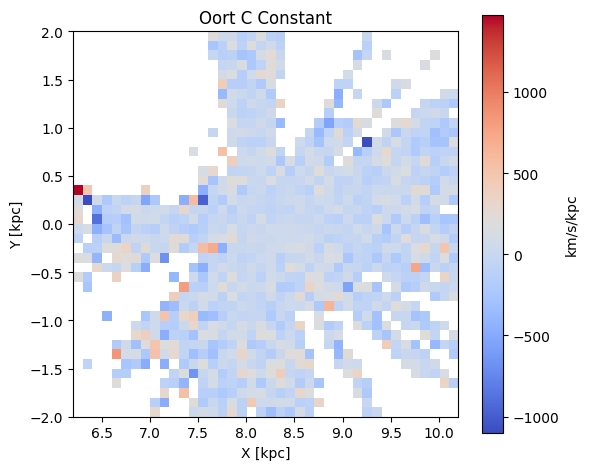

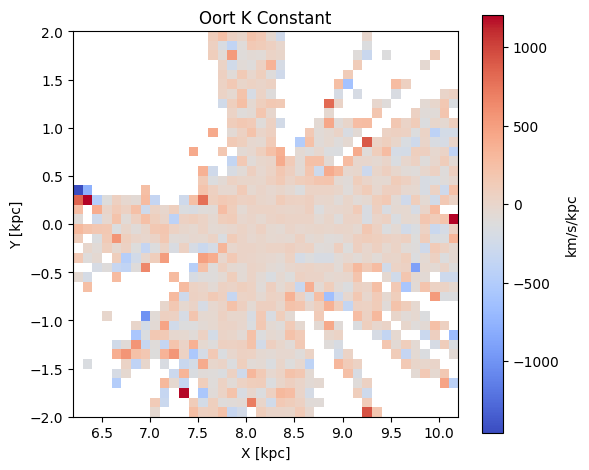

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Parámetros del mapa
grid_size = 0.1  # tamaño del bin en kpc
min_stars = 30   # número mínimo de estrellas por celda

# Definir los límites del mapa centrado en el Sol
x0, y0 = 8.2, 0.0
xlim = (x0 - 2, x0 + 2)
ylim = (y0 - 2, y0 + 2)

# Crear grilla de bins
xbins = np.arange(xlim[0], xlim[1], grid_size)
ybins = np.arange(ylim[0], ylim[1], grid_size)

# Inicializar mapas
A_map = np.full((len(xbins), len(ybins)), np.nan)
B_map = np.full((len(xbins), len(ybins)), np.nan)
C_map = np.full((len(xbins), len(ybins)), np.nan)
K_map = np.full((len(xbins), len(ybins)), np.nan)

# Loop por celdas
for i, xcen in enumerate(xbins):
    for j, ycen in enumerate(ybins):
        # Selección por celda
        cell = df[
            (df["X_gal"] >= xcen) & (df["X_gal"] < xcen + grid_size) &
            (df["Y_gal"] >= ycen) & (df["Y_gal"] < ycen + grid_size)
        ]

        if len(cell) >= min_stars:
            x = cell["X_gal"].values - xcen
            y = cell["Y_gal"].values - ycen
            U = cell["U"].values
            V = cell["V"].values

            X_mat = np.column_stack((x, y))
            regU = LinearRegression().fit(X_mat, U)
            regV = LinearRegression().fit(X_mat, V)

            dU_dx, dU_dy = regU.coef_
            dV_dx, dV_dy = regV.coef_

            A = 0.5 * (dV_dx - dU_dy)
            B = -0.5 * (dV_dx + dU_dy)
            C = 0.5 * (dU_dx + dV_dy)
            K = 0.5 * (dU_dx - dV_dy)

            A_map[i, j] = A
            B_map[i, j] = B
            C_map[i, j] = C
            K_map[i, j] = K

# Función para graficar mapas
def plot_oort_map(data, title, cmap='coolwarm', vmin=None, vmax=None):
    plt.figure(figsize=(6, 5))
    plt.imshow(data.T, origin='lower', extent=(xlim[0], xlim[1], ylim[0], ylim[1]),
               aspect='equal', cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(label='km/s/kpc')
    plt.title(title)
    plt.xlabel('X [kpc]')
    plt.ylabel('Y [kpc]')
    plt.grid(False)
    plt.tight_layout()
    plt.show()

# Graficar cada constante
plot_oort_map(A_map, 'Oort A Constant')
plot_oort_map(B_map, 'Oort B Constant')
plot_oort_map(C_map, 'Oort C Constant')
plot_oort_map(K_map, 'Oort K Constant')
